## State-based optimisation for DQEs

In [3]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.dqe_state import dqe_optimisation
from pulse_vqe_entanglement.plotting_state import plot_dqe_optimisation

### Strong initialisation

Tracing control amplitude graph.
Infidelity: I=3.109e-09, nit=32, success=True, grad_norm=2.225e-05 S=1.464e+01
[outer 00] I=3.368e-02, lam=3.368140e+08, inner_nit=100, inner_success=False, constraint_residual=3.368e-02, S=3.458e+00
[outer 01] I=4.068e-11, lam=3.368140e+08, inner_nit=100, inner_success=False, constraint_residual=3.968e-11, S=5.390e+00
[outer 02] I=2.090e-11, lam=3.368140e+08, inner_nit=96, inner_success=True, constraint_residual=1.990e-11, S=5.337e+00


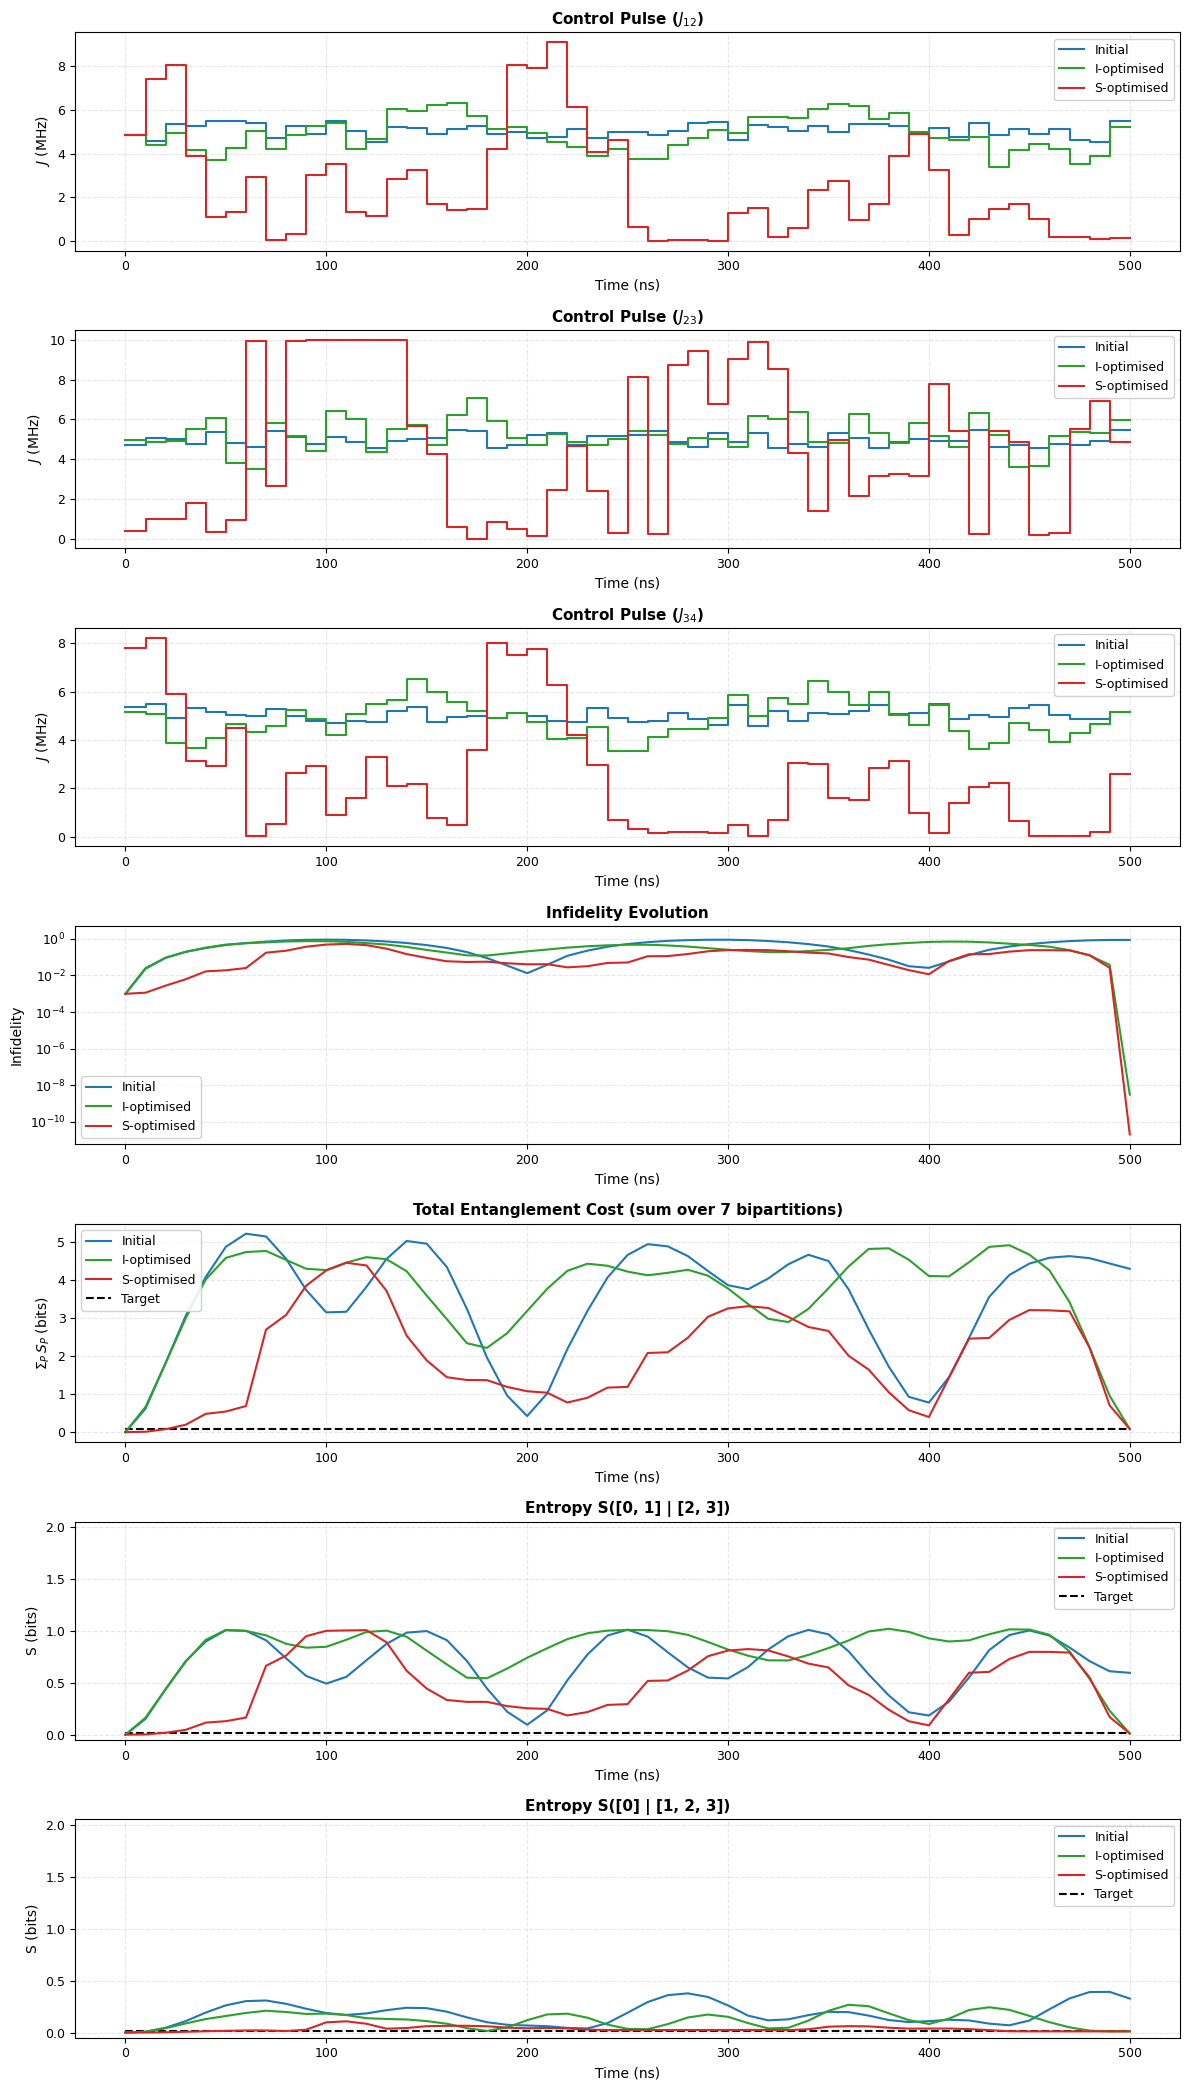

In [7]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0, 1016.0, 1024.0], dtype=float),
    initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
                            0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.complex128),  # |0011⟩
    #initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
    #                        0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0] / np.sqrt(2), dtype=np.complex128),  # (|0011⟩ + |1100⟩) / √2
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=500.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="linear",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e10,
    n_outer=3,
    inner_maxiter=100,
    fd_eps=1e-6,

    dqe_plot_partitions=[(0,1), (0,)]
)

results = dqe_optimisation(config)
plot_dqe_optimisation(results)

### Weak initialisation

Tracing control amplitude graph.
Infidelity: I=9.868e-04, nit=4, success=True, grad_norm=9.331e-06 S=8.993e-06
[outer 00] I=9.868e-04, lam=9.867636e+08, inner_nit=10, inner_success=True, constraint_residual=9.868e-04, S=0.000e+00
[outer 01] I=9.866e-04, lam=1.973400e+09, inner_nit=28, inner_success=True, constraint_residual=9.866e-04, S=5.099e-08
[outer 02] I=9.866e-04, lam=2.960035e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=5.096e-08
[outer 03] I=9.866e-04, lam=3.946671e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=5.098e-08
[outer 04] I=9.866e-04, lam=4.933307e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=5.096e-08
[outer 05] I=9.866e-04, lam=5.919943e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=5.097e-08
[outer 06] I=9.866e-04, lam=6.906579e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=5.094e-08
[outer 07] I=9.866e-04, lam=7.893215e+09, inner_nit=1, inner_

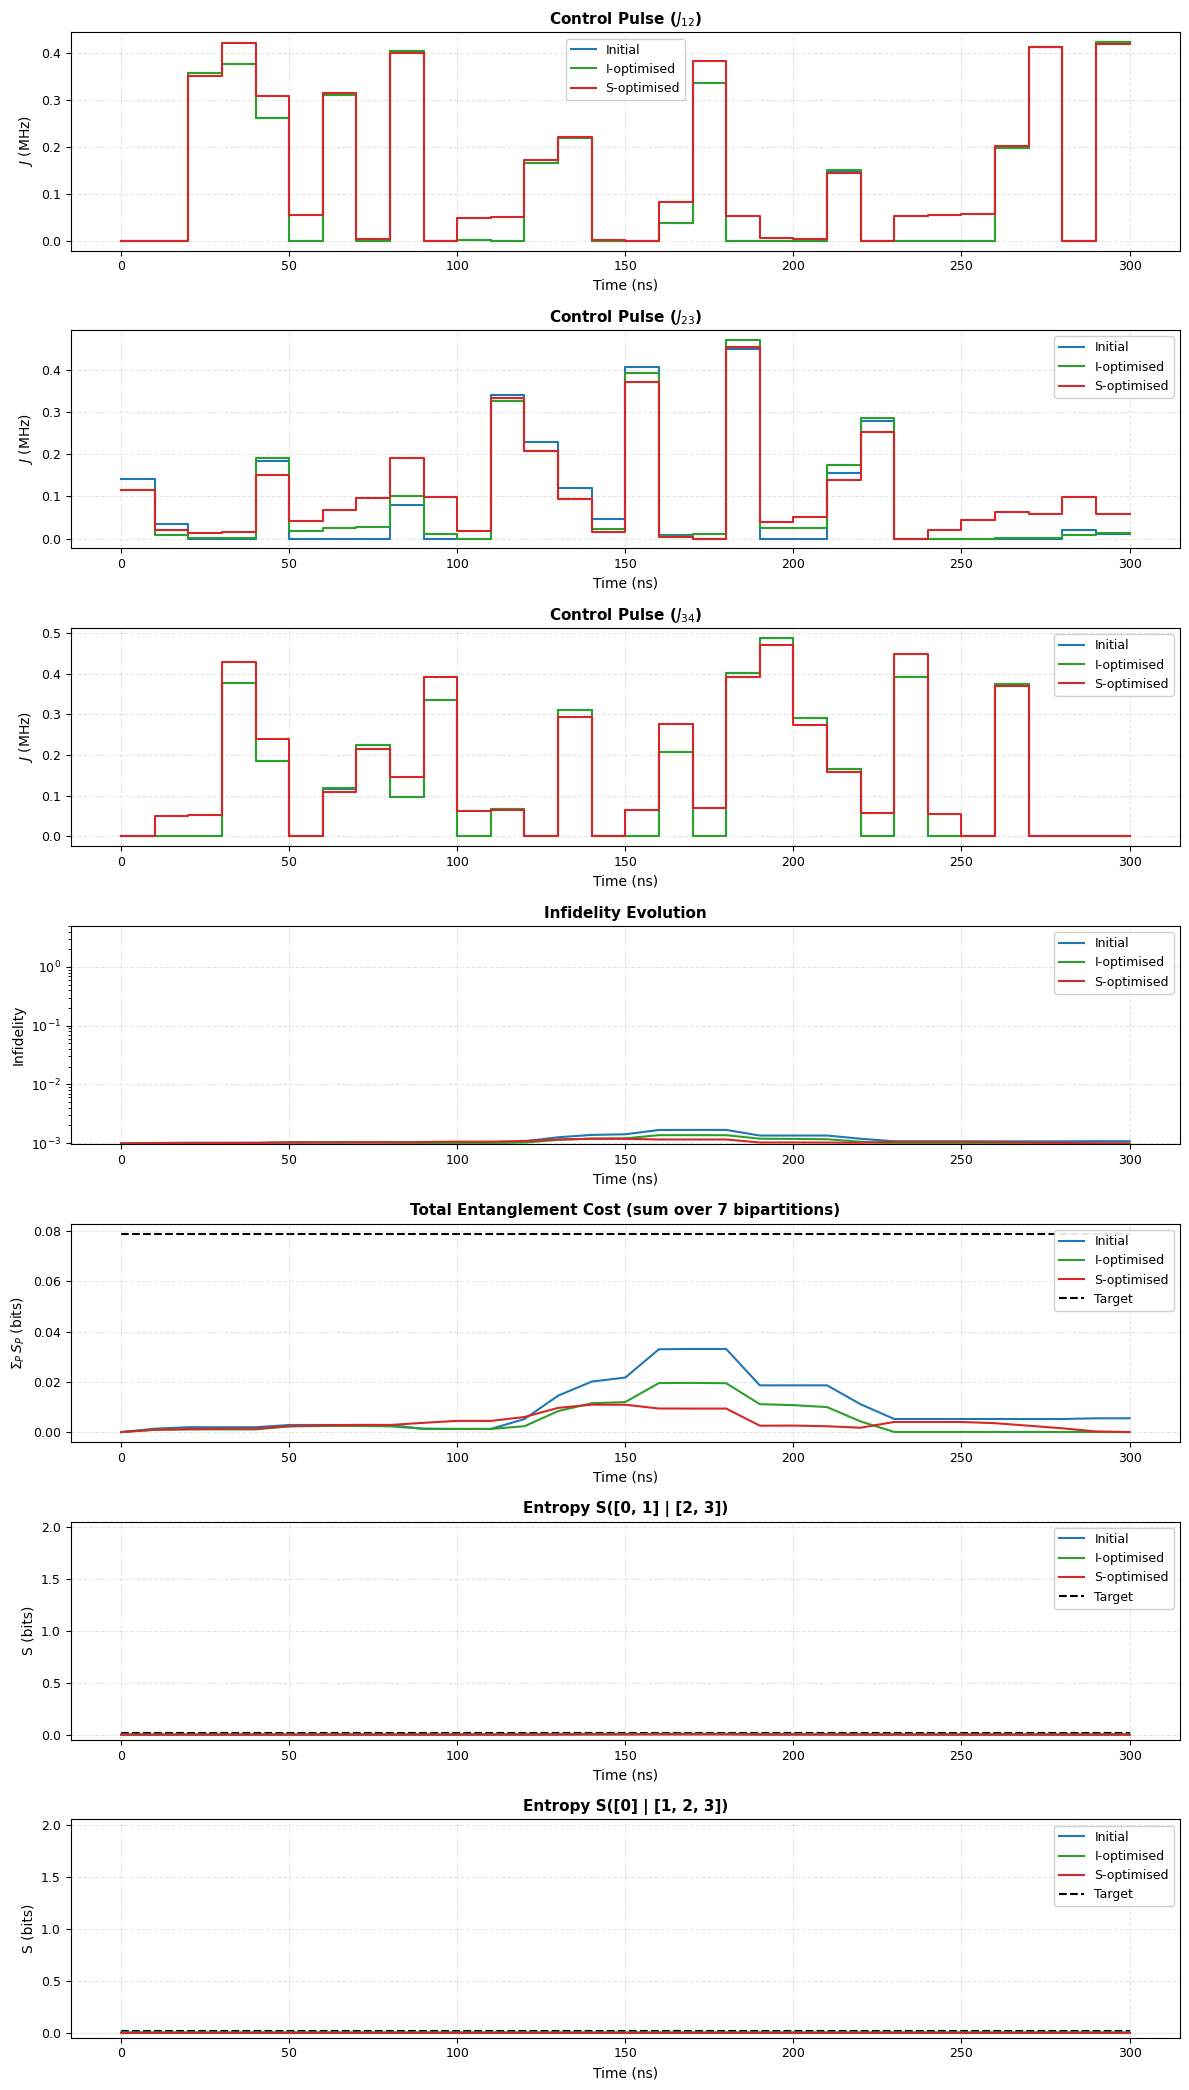

In [ ]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0, 1016.0, 1024.0], dtype=float),
    initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
                            0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.complex128),  # |0011⟩
    #initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
    #                        0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0] / np.sqrt(2), dtype=np.complex128),  # (|0011⟩ + |1100⟩) / √2
    theta_target=0.01 * np.pi,
    n_time_steps=30,
    n_discretisation=1,
    T=300.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    J_init_mean=-1.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e12,
    n_outer=10,
    inner_maxiter=500,
    fd_eps=1e-6,

    dqe_plot_partitions=[(0,1), (0,)]
)

results = dqe_optimisation(config)
plot_dqe_optimisation(results)

### Allow negative J

Tracing control amplitude graph.
Infidelity: I=9.867e-04, nit=7, success=True, grad_norm=1.017e-05 S=1.843e-04
[outer 00] I=9.866e-04, lam=9.866488e+08, inner_nit=36, inner_success=True, constraint_residual=9.866e-04, S=1.215e-10
[outer 01] I=9.866e-04, lam=1.973285e+09, inner_nit=25, inner_success=True, constraint_residual=9.866e-04, S=3.411e-08
[outer 02] I=9.866e-04, lam=2.959922e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=3.410e-08
[outer 03] I=9.866e-04, lam=3.946558e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=3.411e-08
[outer 04] I=9.866e-04, lam=4.933195e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=3.410e-08
[outer 05] I=9.866e-04, lam=5.919832e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=3.411e-08
[outer 06] I=9.866e-04, lam=6.906468e+09, inner_nit=1, inner_success=True, constraint_residual=9.866e-04, S=3.410e-08
[outer 07] I=9.866e-04, lam=7.893105e+09, inner_nit=1, inner_

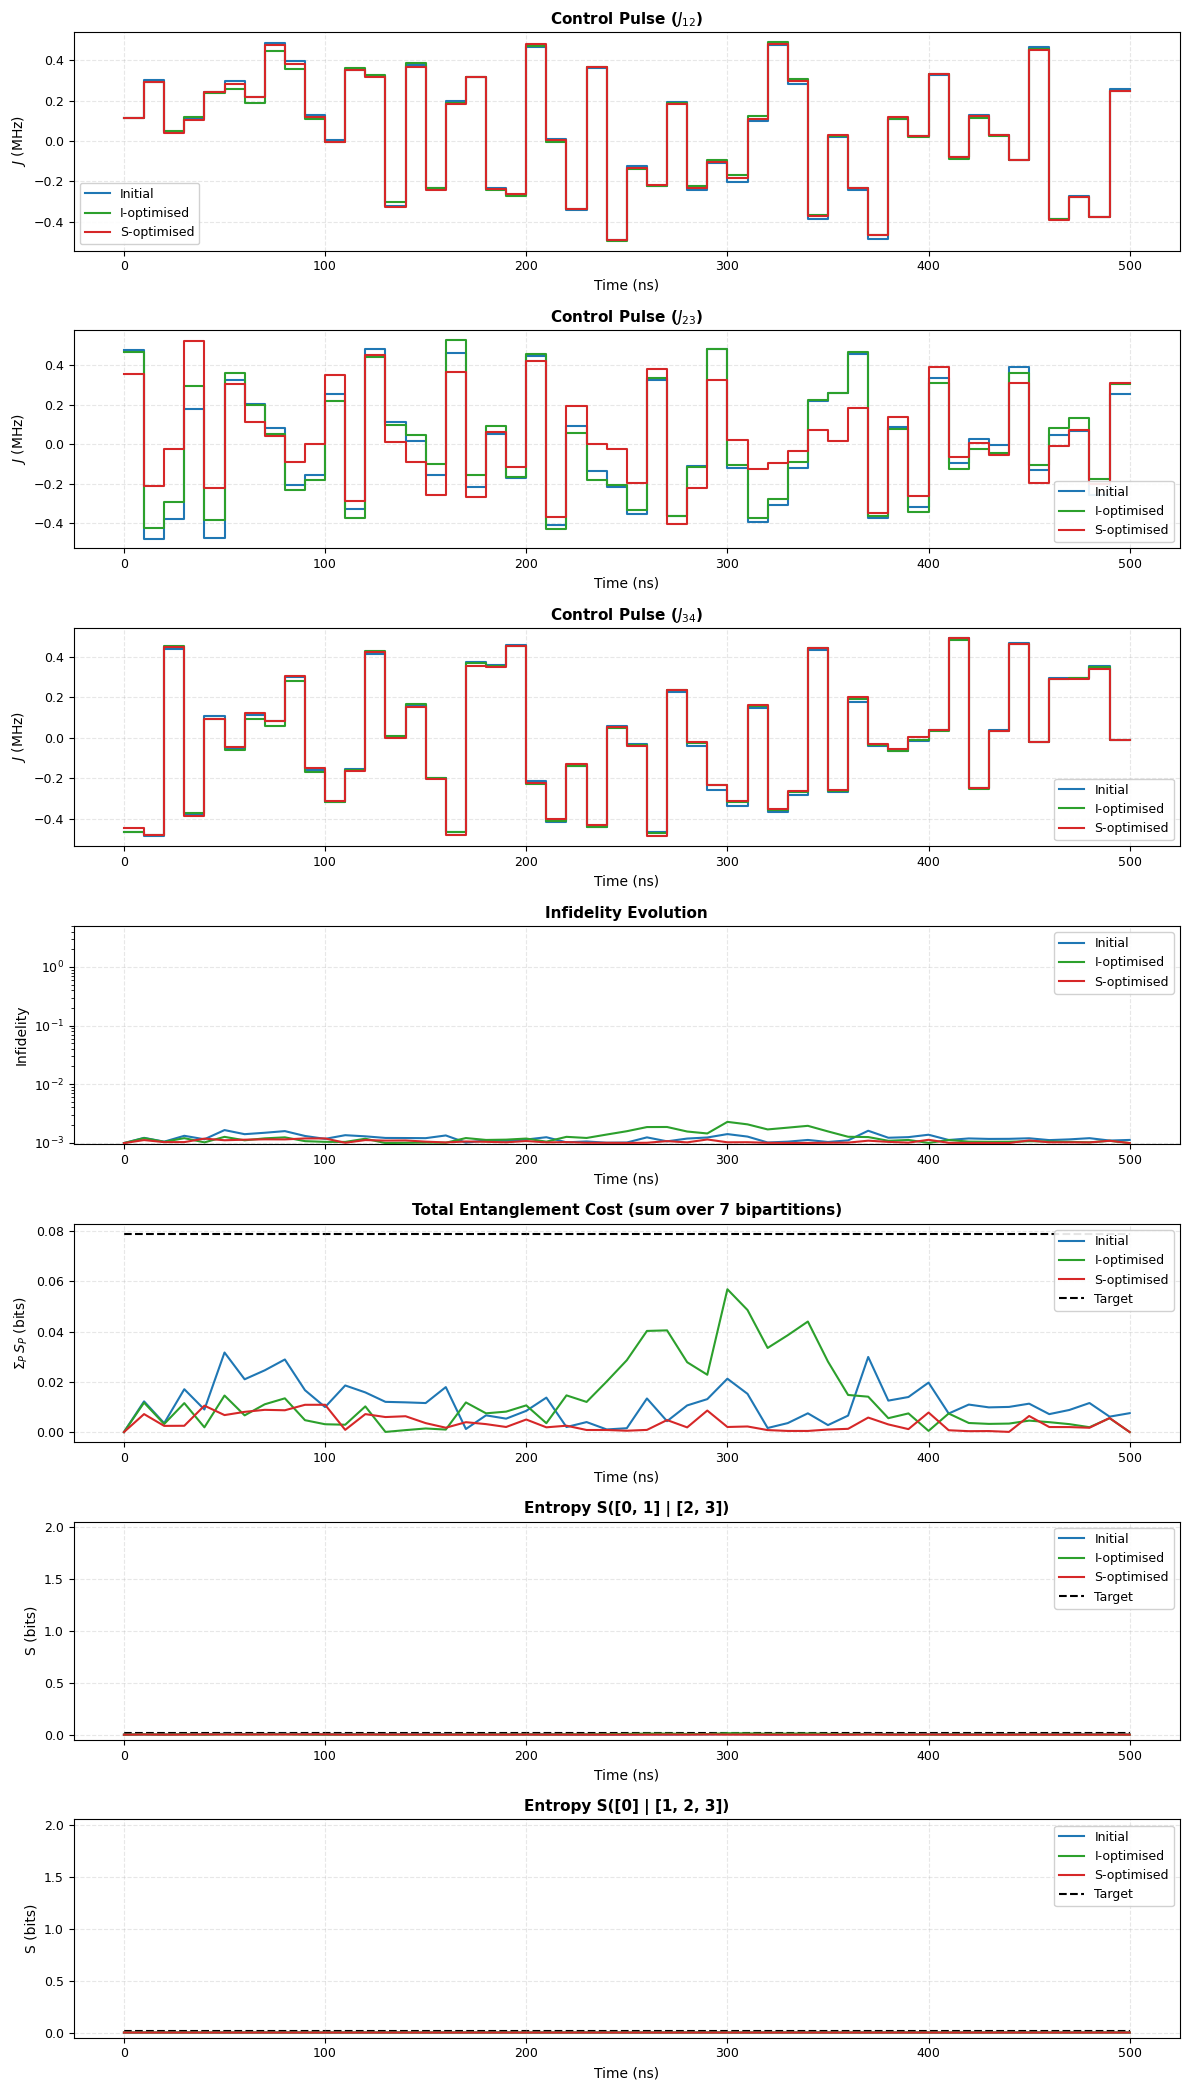

In [ ]:
config = SimulationConfig(
    zeeman_splittings=np.array([1000.0, 1008.0, 1016.0, 1024.0], dtype=float),
    initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
                            0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.complex128),  # |0011⟩
    #initial_state=np.array([0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0,
    #                        0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0] / np.sqrt(2), dtype=np.complex128),  # (|0011⟩ + |1100⟩) / √2
    theta_target=0.01 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=500.0,
    max_drive_strength=0.0,
    J_max=5.0,
    J_min=-5.0,
    J_init_scale=1e-1,
    J_init_mean=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    entanglement_optimisation=True,
    state_ent_measure="von_neumann",
    #extra_ent_measures=["linear"],
    J_init_seed=None,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e12,
    n_outer=10,
    inner_maxiter=500,
    fd_eps=1e-6,

    dqe_plot_partitions=[(0,1), (0,)]
)

results = dqe_optimisation(config)
plot_dqe_optimisation(results)